<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_16/lab_work_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Завдання 1 та 2: Кореляція Пірсона і Спірмена ---


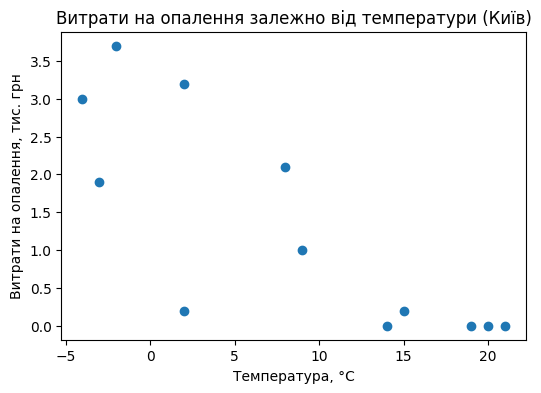

Пірсон: r = -0.806, p-value = 1.5285e-03
Спірмен: rho = -0.827, p-value = 9.0770e-04
95% довірчий інтервал для Пірсона: (-0.944, -0.433)

--- Завдання 3: Кореляційна матриця ---
Пірсон:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.000000,-0.986781,-0.806495
опалювальні_дні,-0.986781,1.000000,0.787166
витрати_на_опалення,-0.806495,0.787166,1.000000



Спірмен:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.000000,-0.982456,-0.826918
опалювальні_дні,-0.982456,1.000000,0.821560
витрати_на_опалення,-0.826918,0.821560,1.000000



--- Завдання 5: Перевірка на викиди ---
З викидом - Пірсон: r = -0.618, p-value = 3.2249e-02
З викидом - Спірмен: rho = -0.866, p-value = 2.6853e-04


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

np.random.seed(1)
city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })
climate = pd.DataFrame(rows)

print("--- Завдання 1 та 2: Кореляція Пірсона і Спірмена ---")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(climate["температура"], climate["витрати_на_опалення"])
ax.set_xlabel("Температура, °C")
ax.set_ylabel("Витрати на опалення, тис. грн")
ax.set_title("Витрати на опалення залежно від температури (Київ)")
plt.show()

r_res = pearsonr(climate["температура"], climate["витрати_на_опалення"])
rho_res = spearmanr(climate["температура"], climate["витрати_на_опалення"])

print(f"Пірсон: r = {r_res.statistic:.3f}, p-value = {r_res.pvalue:.4e}")
print(f"Спірмен: rho = {rho_res.statistic:.3f}, p-value = {rho_res.pvalue:.4e}")

ci = r_res.confidence_interval(confidence_level=0.95)
print(f"95% довірчий інтервал для Пірсона: ({ci.low:.3f}, {ci.high:.3f})")

print("\n--- Завдання 3: Кореляційна матриця ---")
subset = climate[["температура", "опалювальні_дні", "витрати_на_опалення"]]
print("Пірсон:")
display(subset.corr(method="pearson"))
print("\nСпірмен:")
display(subset.corr(method="spearman"))

print("\n--- Завдання 5: Перевірка на викиди ---")
climate_outlier = climate.copy()
climate_outlier.loc[0, "витрати_на_опалення"] *= 5  # аварія на котельні в січні

r_out = pearsonr(climate_outlier["температура"], climate_outlier["витрати_на_опалення"])
rho_out = spearmanr(climate_outlier["температура"], climate_outlier["витрати_на_опалення"])

print(f"З викидом - Пірсон: r = {r_out.statistic:.3f}, p-value = {r_out.pvalue:.4e}")
print(f"З викидом - Спірмен: rho = {rho_out.statistic:.3f}, p-value = {rho_out.pvalue:.4e}")

## Відповіді на контрольні питання

1. **У чому полягає механіка коефіцієнта кореляції Пірсона?**
   - Коефіцієнт Пірсона вимірює силу та напрямок лінійного зв'язку між двома змінними. У чисельнику він обчислює коваріацію (спільну мінливість обох змінних навколо їхніх середніх), а в знаменнику ділить її на добуток стандартних відхилень обох змінних, що нормує результат до діапазону від -1 до 1.

2. **Чому коефіцієнт Спірмена рахують на рангах, а не на самих значеннях?**
   - Заміна вихідних числових значень їхніми порядковими рангами дозволяє нівелювати вплив нелінійних монотонних залежностей та сильних викидів, роблячи цей коефіцієнт стійкішим до аномальних значень порівняно з коефіцієнтом Пірсона.

3. **Наведіть приклад ситуації, де r близьке до 0, а сильний зв'язок існує.**
   - Класичним прикладом є нелінійний U-подібна або параболічна залежність (наприклад, продуктивність праці залежно від рівня стресу: і занадто низький, і занадто високий стрес знижують результативність). У такому випадку лінійний зв'язок відсутній (r близько 0), хоча тісний функціональний зв'язок очевидний.

4. **Чому сильна кореляція не є доказом причинно-наслідкового зв'язку?**
   - Високий коефіцієнт кореляції показує лише статистичну супутність змінних. Причинно-наслідковий зв'язок може бути відсутнім через наявність спільного прихованого чинника (конфаундера) або через зворотну дію, коли наслідок впливає на причину.